# Generate case-study figures

Run the cells from top to bottom. This notebook reads `data/raw/Data for Task 1.csv` and saves publication-ready figures in `reports/figures/`. It also prints cross-validation and test metrics for comparison with the report.

The model settings and five-fold split match the project scripts. Model selection and threshold analysis use the training partition; the held-out test set is reserved for final evaluation and descriptive permutation analysis.


In [1]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

from sklearn.base import clone
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay, f1_score, precision_score, recall_score,
    precision_recall_curve, make_scorer,
)
from sklearn.model_selection import (
    StratifiedKFold, cross_validate, cross_val_predict, train_test_split
)
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier, plot_tree
from IPython.display import display

# Find the project root whether Jupyter was launched from the root or notebooks/.
PROJECT_ROOT = next(
    (p for p in [Path.cwd(), *Path.cwd().parents]
     if (p / "data" / "raw" / "Data for Task 1.csv").exists()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Could not find data/raw/Data for Task 1.csv. Save this notebook in the project and launch Jupyter from the project folder."
    )

DATA_PATH = PROJECT_ROOT / "data" / "raw" / "Data for Task 1.csv"
FIGURE_DIR = PROJECT_ROOT / "reports" / "figures"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 120, "savefig.dpi": 180, "font.size": 10})
print("Project:", PROJECT_ROOT)
print("Figures:", FIGURE_DIR)


Project: /Users/kiwi/Documents/Codex/2026-10-21/new-chat/completed_project
Figures: /Users/kiwi/Documents/Codex/2026-10-21/new-chat/completed_project/reports/figures


In [2]:
# Load the CSV and drop the blank trailing header that appears in the supplied file.
df = pd.read_csv(DATA_PATH)
df.columns = [str(c).strip() for c in df.columns]
df = df.loc[:, [c and not c.lower().startswith("unnamed:") for c in df.columns]]

required = {"id", "diagnosis"}
missing = required - set(df.columns)
if missing:
    raise ValueError(f"Missing expected columns: {missing}")

# The ID is kept for tracing records, but is not a model feature.
case_ids = df["id"].copy()
y = df["diagnosis"].map({"B": 0, "M": 1})
if y.isna().any():
    raise ValueError("Diagnosis contains labels other than B or M.")
X = df.drop(columns=["id", "diagnosis"]).select_dtypes(include=np.number)
feature_names = X.columns.tolist()

X_train, X_test, y_train, y_test, ids_train, ids_test = train_test_split(
    X, y, case_ids, test_size=0.20, stratify=y, random_state=42
)

print(f"Rows: {len(df)} | Features: {X.shape[1]}")
print("Class counts:", df["diagnosis"].value_counts().to_dict())
print("Missing values:", int(df.isna().sum().sum()))
print("Duplicate rows:", int(df.duplicated().sum()))
print(f"Train: {len(X_train)} | Test: {len(X_test)}")


Rows: 569 | Features: 30
Class counts: {'B': 357, 'M': 212}
Missing values: 0
Duplicate rows: 0
Train: 455 | Test: 114


## 1. Dataset overview

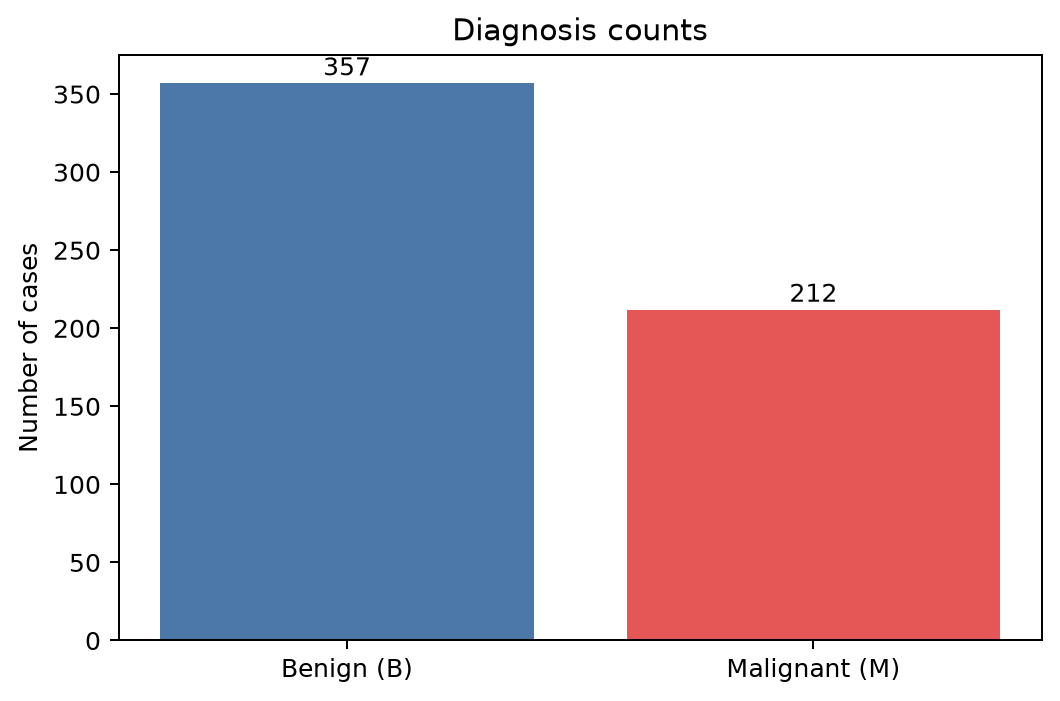

In [3]:
counts = df["diagnosis"].value_counts().reindex(["B", "M"])
fig, ax = plt.subplots(figsize=(6, 4))
colors = ["#4C78A8", "#E45756"]
ax.bar(["Benign (B)", "Malignant (M)"], counts.values, color=colors)
ax.set(title="Diagnosis counts", ylabel="Number of cases")
for i, value in enumerate(counts.values): ax.text(i, value + 5, str(value), ha="center")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "diagnosis_counts.png", bbox_inches="tight")
plt.show()


## 2. Feature comparisons

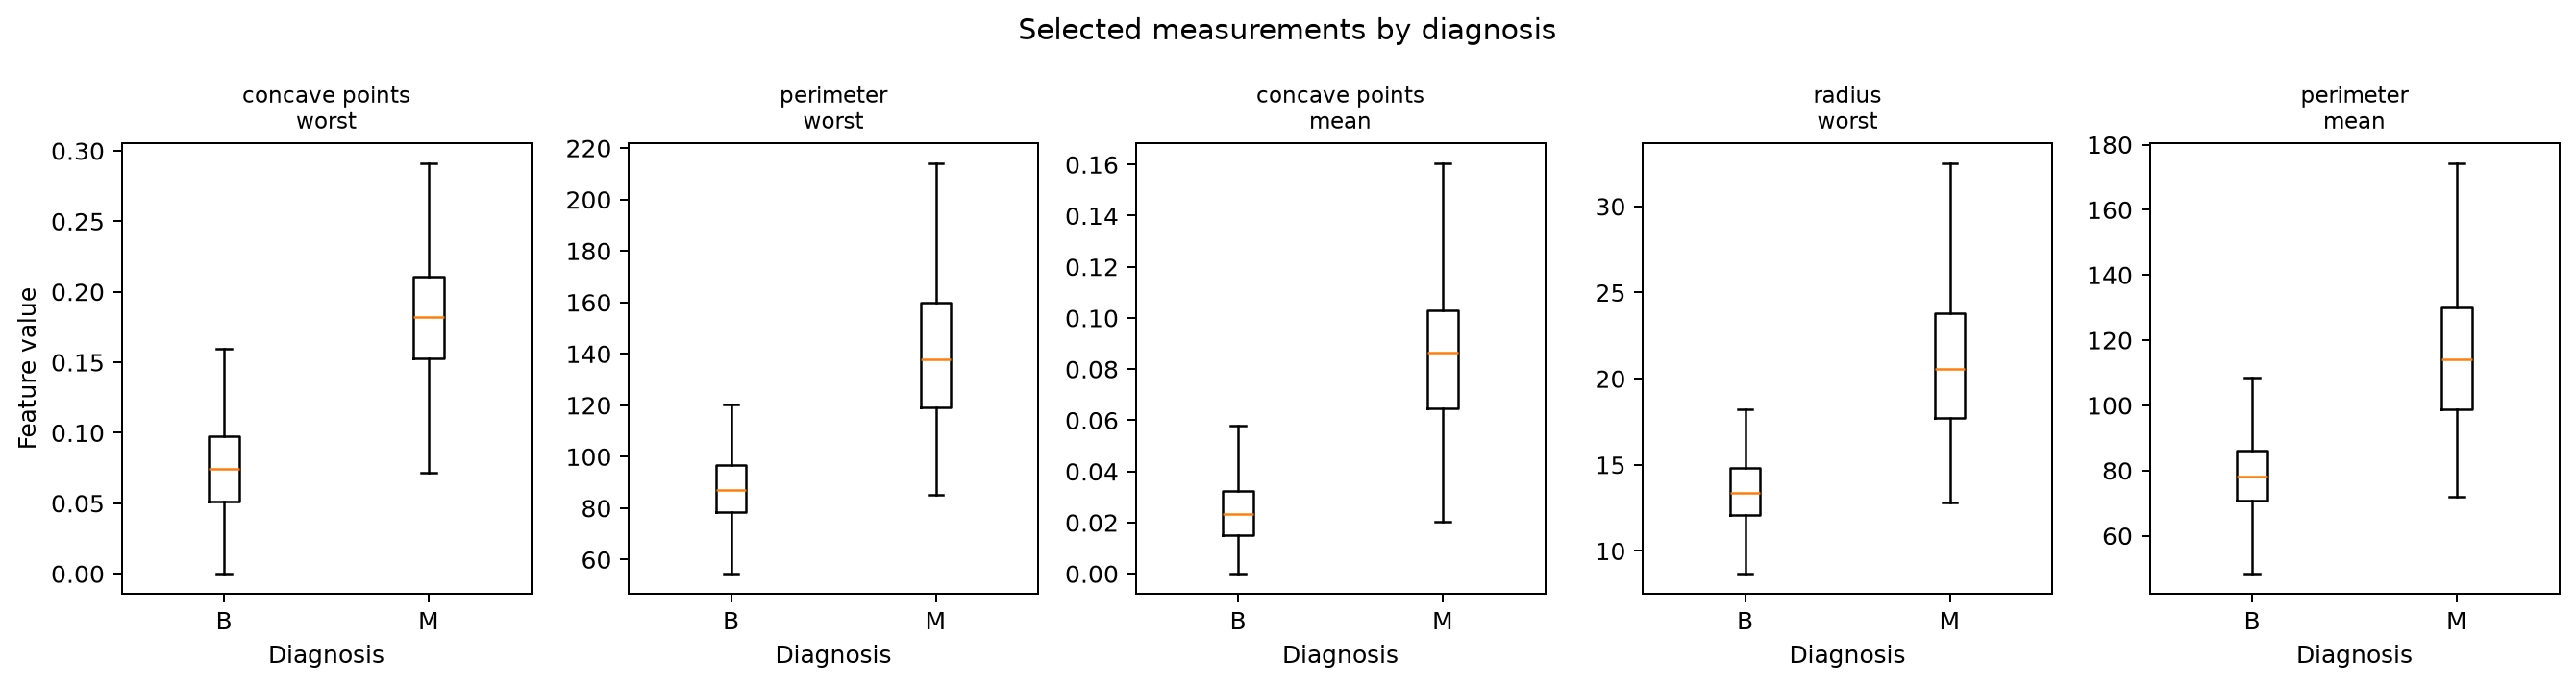

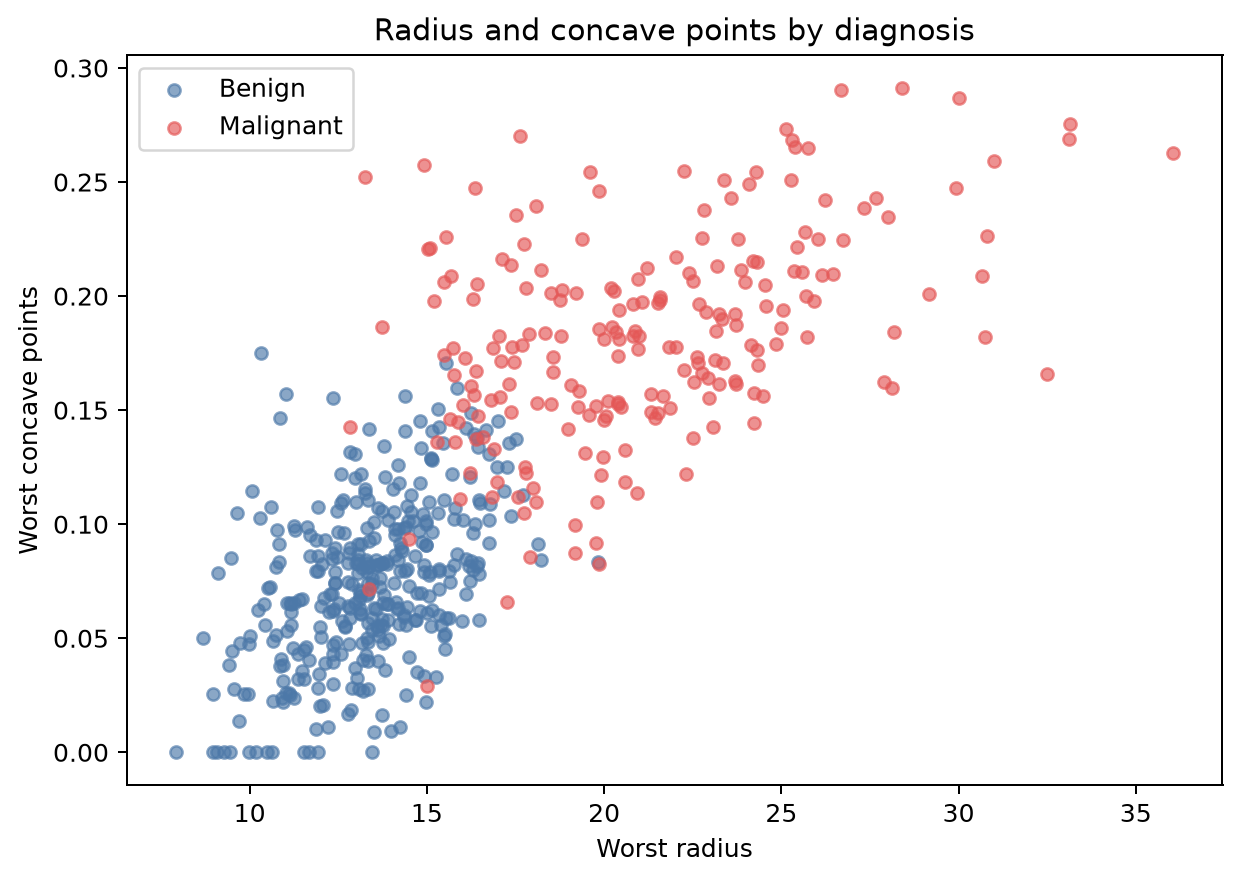

In [4]:
selected_features = [
    "concave points_worst", "perimeter_worst", "concave points_mean",
    "radius_worst", "perimeter_mean",
]
fig, axes = plt.subplots(1, len(selected_features), figsize=(15, 4))
for ax, feature in zip(axes, selected_features):
    values = [df.loc[df.diagnosis == label, feature].dropna() for label in ["B", "M"]]
    ax.boxplot(values, showfliers=False)
    ax.set_xticks([1, 2])
    ax.set_xticklabels(["B", "M"])
    ax.set_title(feature.replace("_", "\n"), fontsize=9)
    ax.set_xlabel("Diagnosis")
axes[0].set_ylabel("Feature value")
fig.suptitle("Selected measurements by diagnosis")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "feature_comparisons.png", bbox_inches="tight")
plt.show()

fig, ax = plt.subplots(figsize=(7, 5))
for label, color, name in [(0, "#4C78A8", "Benign"), (1, "#E45756", "Malignant")]:
    mask = y == label
    ax.scatter(X.loc[mask, "radius_worst"], X.loc[mask, "concave points_worst"],
               s=24, alpha=.65, color=color, label=name)
ax.set(xlabel="Worst radius", ylabel="Worst concave points",
       title="Radius and concave points by diagnosis")
ax.legend()
fig.tight_layout()
fig.savefig(FIGURE_DIR / "radius_vs_concave_points.png", bbox_inches="tight")
plt.show()


## 3. Feature correlation heatmap

The heatmap uses training predictors. It does not use diagnosis labels.

Feature pairs with |r| > 0.90 in training data: 21
          feature_1            feature_2        r
        radius_mean       perimeter_mean 0.997815
       radius_worst      perimeter_worst 0.993719
        radius_mean            area_mean 0.986740
     perimeter_mean            area_mean 0.985960
       radius_worst           area_worst 0.983107
    perimeter_worst           area_worst 0.976665
          radius_se         perimeter_se 0.974705
     perimeter_mean      perimeter_worst 0.970006
     perimeter_mean         radius_worst 0.969332
        radius_mean         radius_worst 0.969256
        radius_mean      perimeter_worst 0.964439
          area_mean         radius_worst 0.960725
          area_mean           area_worst 0.958177
          area_mean      perimeter_worst 0.956714
          radius_se              area_se 0.951558
     perimeter_mean           area_worst 0.941085
        radius_mean           area_worst 0.940515
       perimeter_se              area_se 0.939162

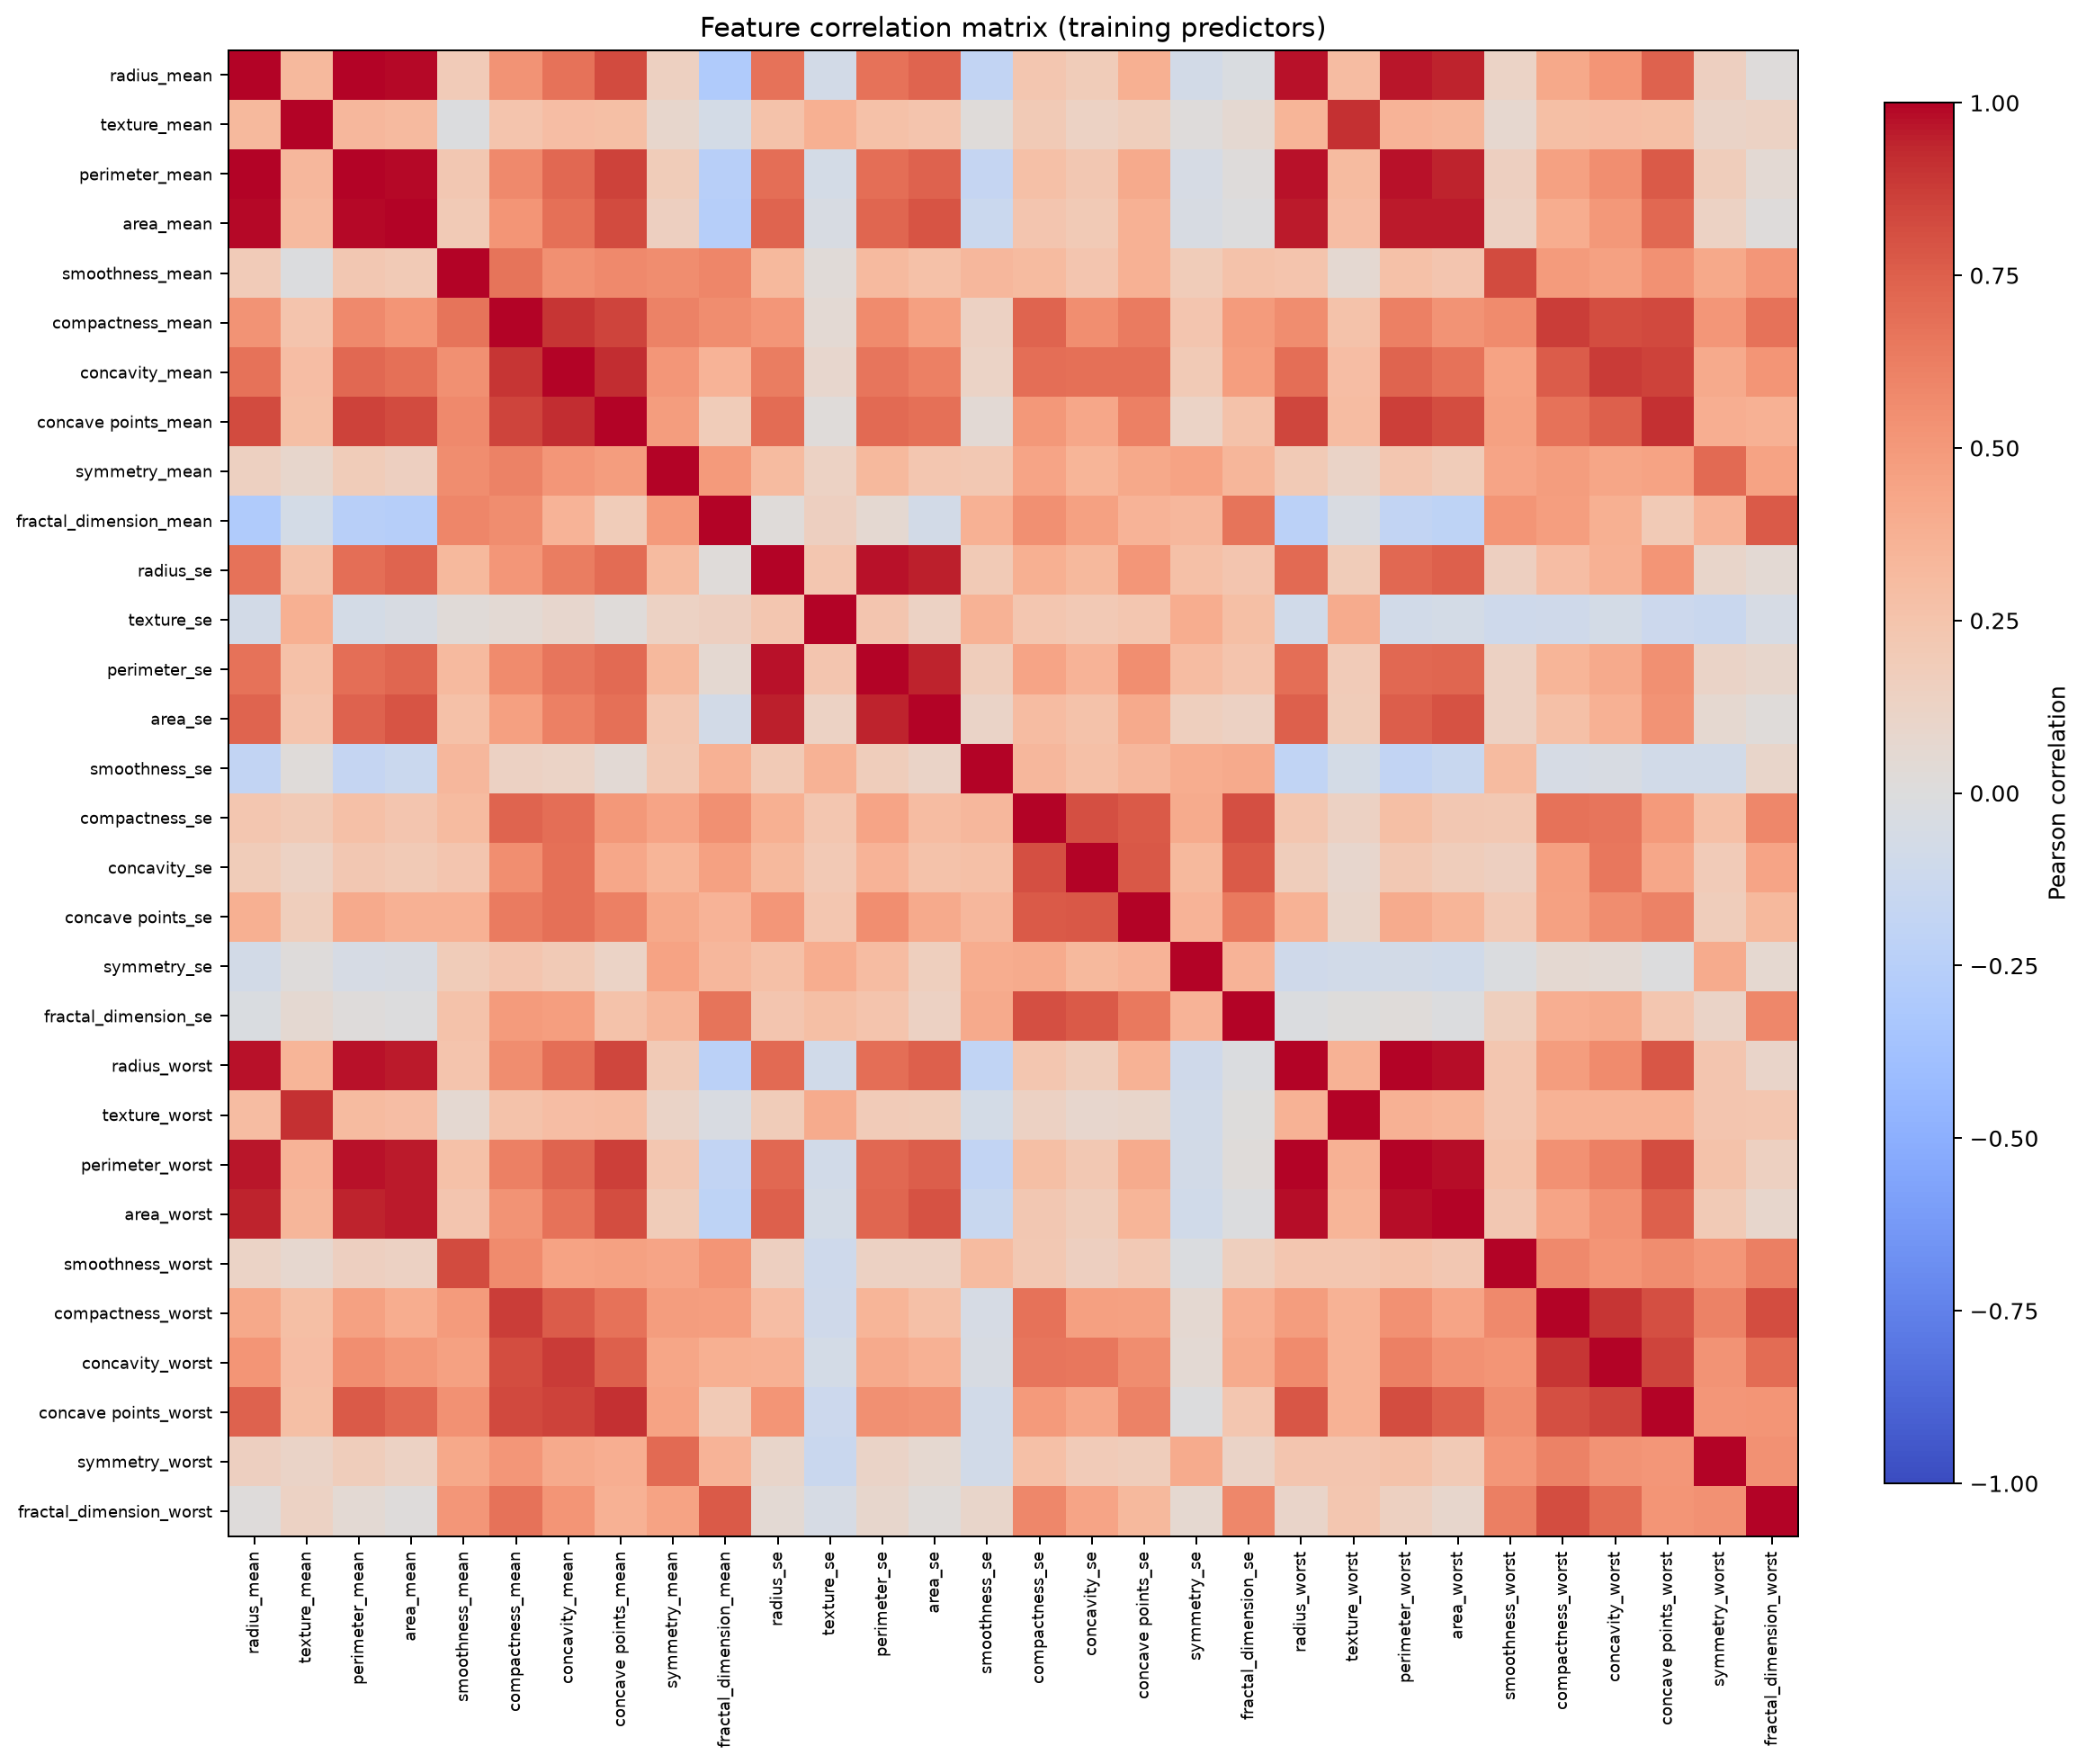

In [5]:
corr = X_train.corr(numeric_only=True)
upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
high_pairs = [(a, b, upper.loc[a, b]) for a in upper.index for b in upper.columns
              if pd.notna(upper.loc[a, b]) and abs(upper.loc[a, b]) > .90]
print(f"Feature pairs with |r| > 0.90 in training data: {len(high_pairs)}")
print(pd.DataFrame(high_pairs, columns=["feature_1", "feature_2", "r"])
      .assign(abs_r=lambda x: x.r.abs()).sort_values("abs_r", ascending=False)
      .drop(columns="abs_r").to_string(index=False))

fig, ax = plt.subplots(figsize=(13, 11))
image = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1, aspect="auto")
ax.set_xticks(range(len(feature_names)), feature_names, rotation=90, fontsize=7)
ax.set_yticks(range(len(feature_names)), feature_names, fontsize=7)
ax.set_title("Feature correlation matrix (training predictors)")
fig.colorbar(image, ax=ax, fraction=.04, label="Pearson correlation")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "feature_correlation_heatmap.png", bbox_inches="tight")
plt.show()


## 4. Cross-validation and interpretable candidate models

The splitter uses five stratified folds with shuffling and random seed 42, matching the project comparison script. Scaling stays inside the logistic-regression pipeline, so each fold fits it only on that fold’s training portion.

In [6]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

models = {
    "Dummy baseline": DummyClassifier(strategy="most_frequent"),
    "Logistic regression": make_pipeline(
        StandardScaler(), LogisticRegression(C=1.0, max_iter=5000, random_state=42)
    ),
    "Shallow decision tree": DecisionTreeClassifier(max_depth=3, random_state=42),
    "Random forest": RandomForestClassifier(n_estimators=300, random_state=42, n_jobs=-1),
}
scoring = {
    "f1": make_scorer(f1_score, zero_division=0),
    "precision": make_scorer(precision_score, zero_division=0),
    "recall": make_scorer(recall_score, zero_division=0),
}
rows=[]
for name, estimator in models.items():
    scores = cross_validate(estimator, X_train, y_train, cv=cv, scoring=scoring,
                            error_score="raise")
    rows.append({"Model": name, **{
        f"{metric} mean": scores[f"test_{metric}"].mean() for metric in scoring
    }, **{f"{metric} SD": scores[f"test_{metric}"].std() for metric in scoring}})
cv_results = pd.DataFrame(rows).set_index("Model")
display(cv_results.round(3))


,f1 mean,precision mean,recall mean,f1 SD,precision SD,recall SD
Model,,,,,,
Dummy baseline,0.000,0.000,0.000,0.000,0.000,0.000
Logistic regression,0.964,0.977,0.953,0.021,0.028,0.040
Shallow decision tree,0.888,0.926,0.859,0.041,0.028,0.082
Random forest,0.946,0.958,0.935,0.023,0.022,0.039


## 5. Decision tree and sparse L1 model

/Users/kiwi/Desktop/model-engineering-breast-cancer/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/Users/kiwi/Desktop/model-engineering-breast-cancer/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1407: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(
/Users/kiwi/Desktop/model-engineering-breast-cancer/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warn

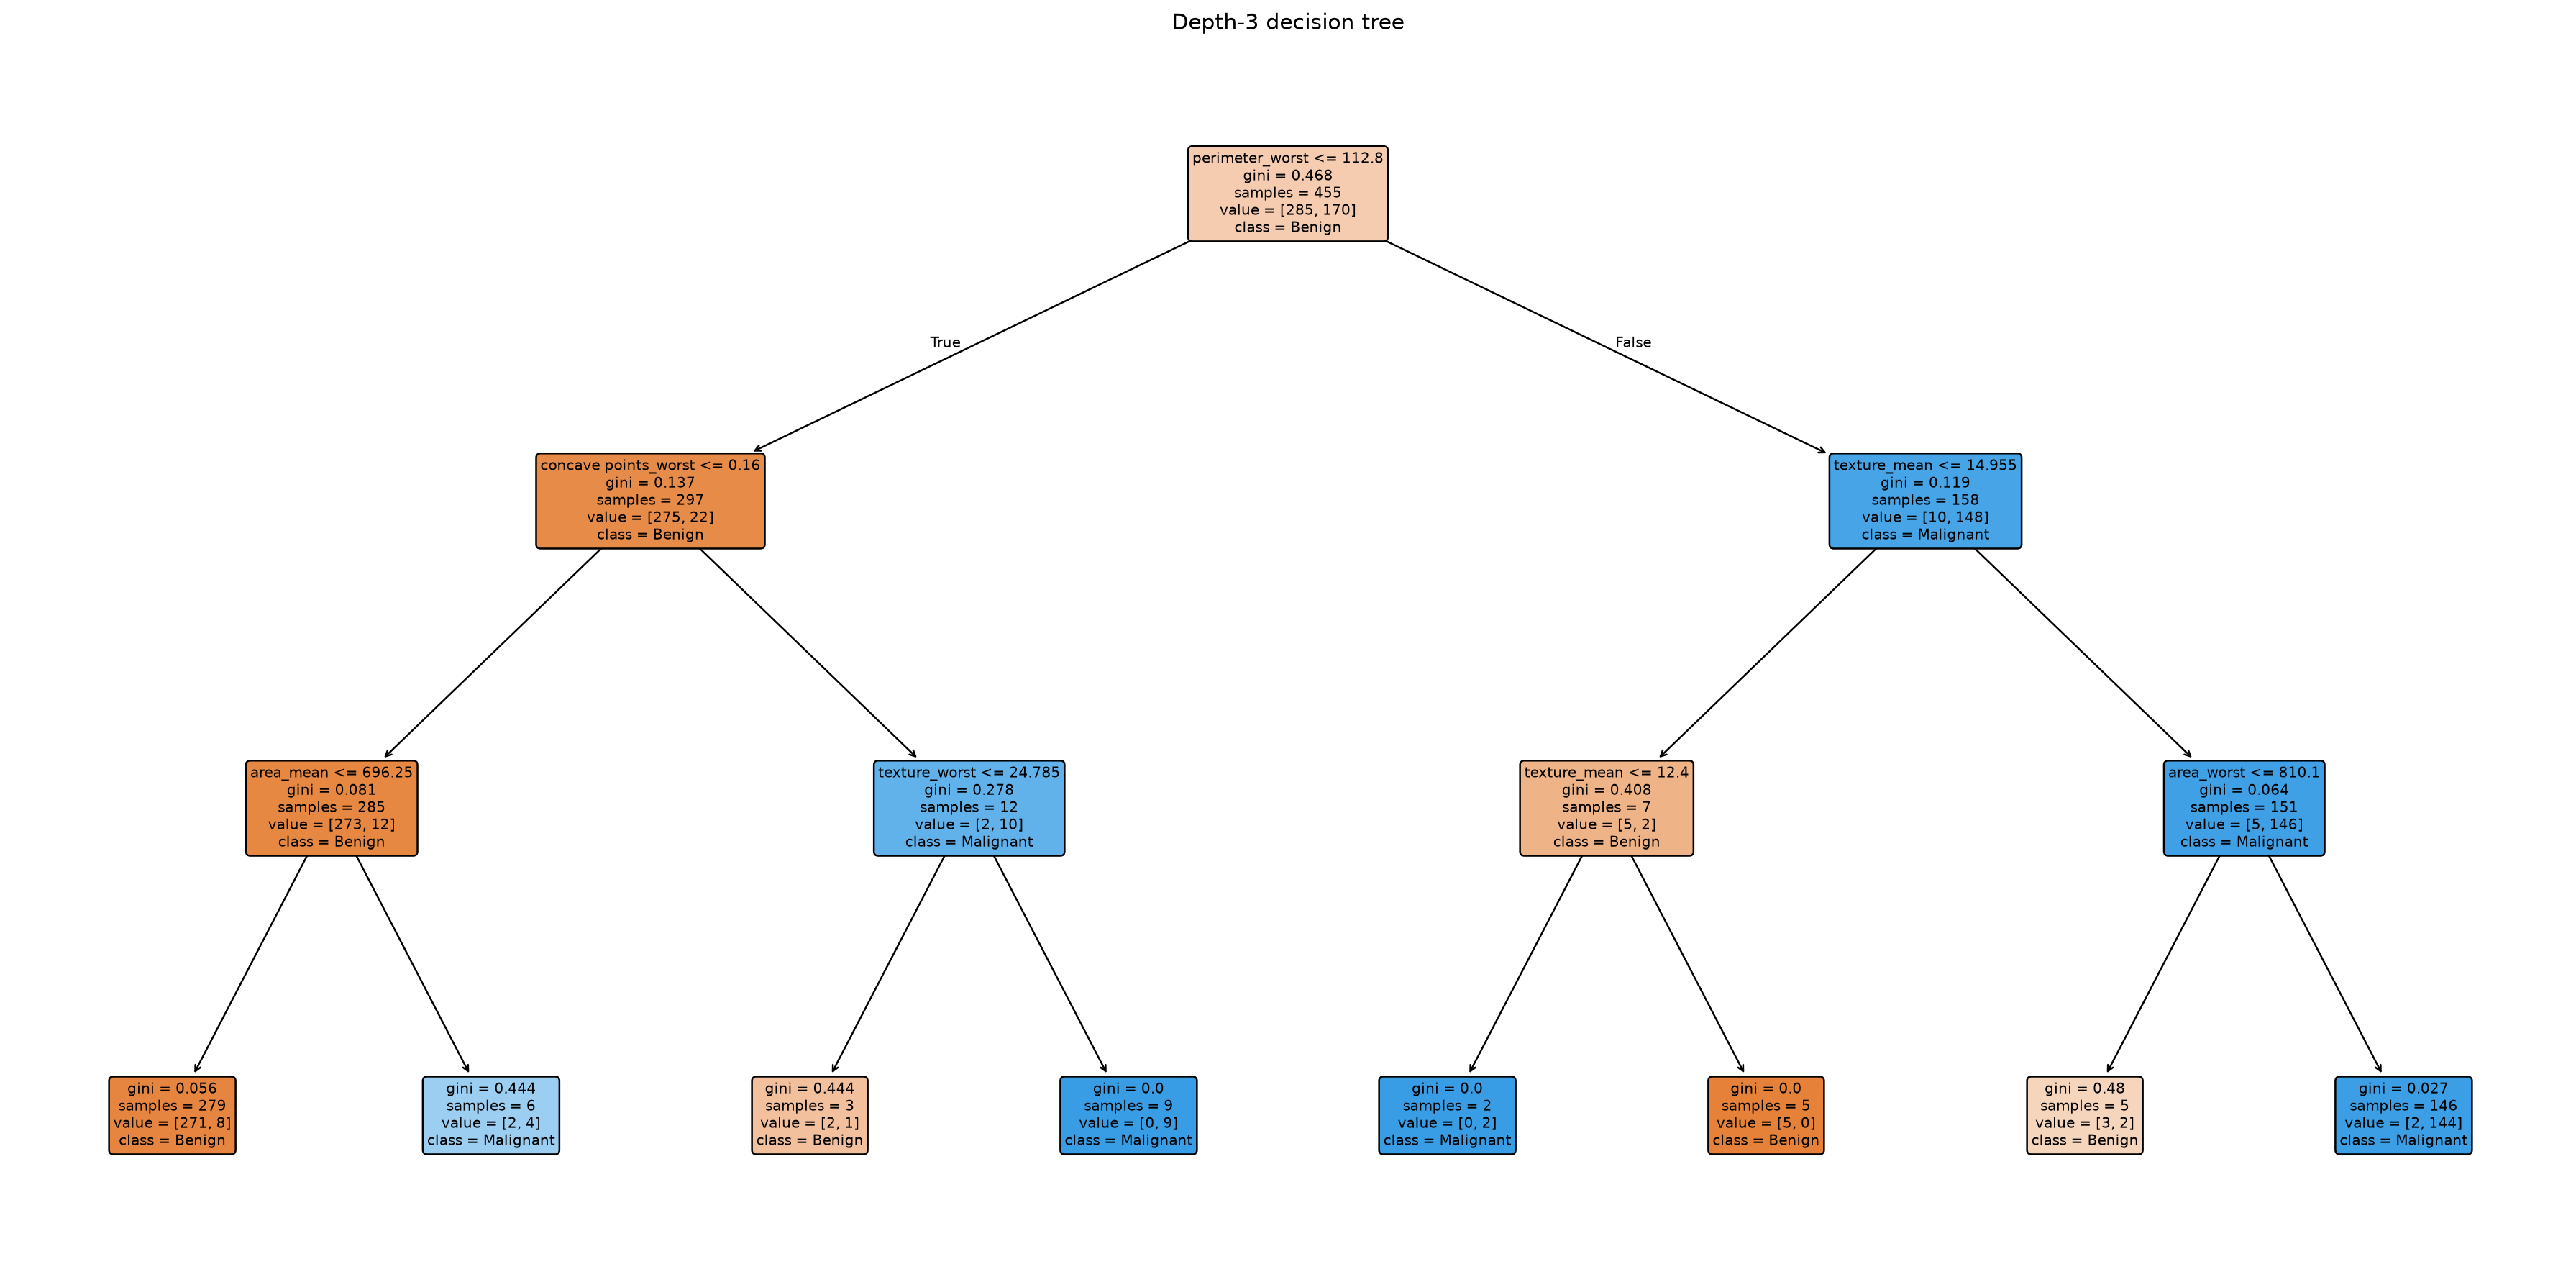

,standardized coefficient
radius_worst,2.118948
concave points_mean,0.976743
texture_worst,0.695876
concave points_worst,0.444193
radius_se,0.301031
symmetry_worst,0.255640
smoothness_worst,0.176490


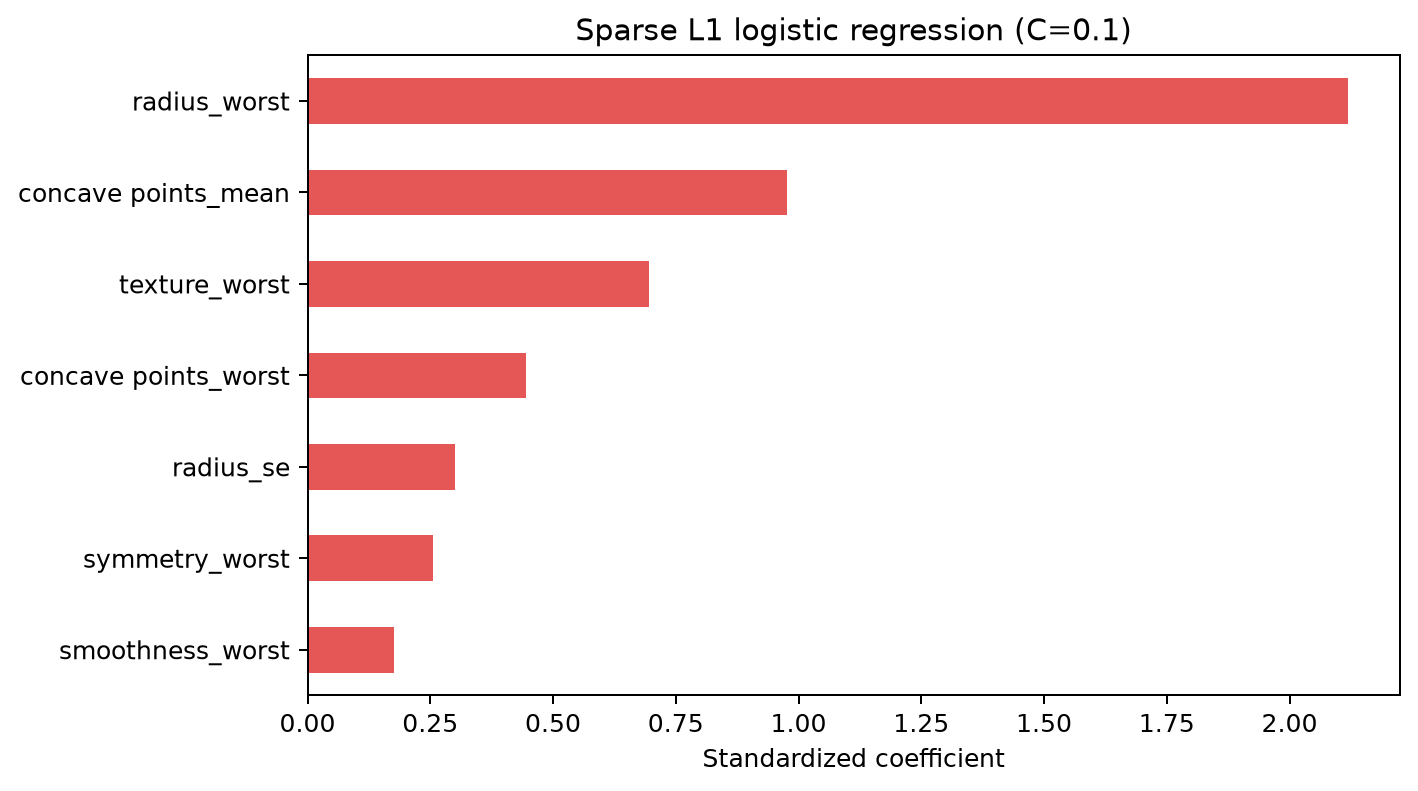

In [7]:
tree = clone(models["Shallow decision tree"]).fit(X_train, y_train)
fig, ax = plt.subplots(figsize=(20, 10))
plot_tree(tree, feature_names=feature_names, class_names=["Benign", "Malignant"],
          filled=True, rounded=True, fontsize=8, ax=ax)
ax.set_title("Depth-3 decision tree")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "decision_tree_depth3.png", bbox_inches="tight")
plt.show()

l1_model = make_pipeline(
    StandardScaler(),
    LogisticRegression(penalty="l1", C=0.1, solver="liblinear", max_iter=5000, random_state=42)
)
l1_scores = cross_validate(l1_model, X_train, y_train, cv=cv, scoring=scoring, error_score="raise")
l1_model.fit(X_train, y_train)
l1_lr = l1_model.named_steps["logisticregression"]
l1_coef = pd.Series(l1_lr.coef_[0], index=feature_names)
selected_l1 = l1_coef[l1_coef.abs() > 1e-10].sort_values(key=np.abs, ascending=False)
print("L1 CV F1: {:.3f} ± {:.3f}".format(l1_scores["test_f1"].mean(), l1_scores["test_f1"].std()))
print(f"Features retained: {len(selected_l1)} / {len(feature_names)}")
display(selected_l1.rename("standardized coefficient").to_frame())

fig, ax = plt.subplots(figsize=(8, 4.5))
selected_l1.sort_values().plot.barh(ax=ax, color=["#4C78A8" if v < 0 else "#E45756" for v in selected_l1.sort_values()])
ax.axvline(0, color="black", linewidth=.8)
ax.set(title="Sparse L1 logistic regression (C=0.1)", xlabel="Standardized coefficient")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "logistic_l1_coefficients.png", bbox_inches="tight")
plt.show()


## 6. Logistic-regression coefficients

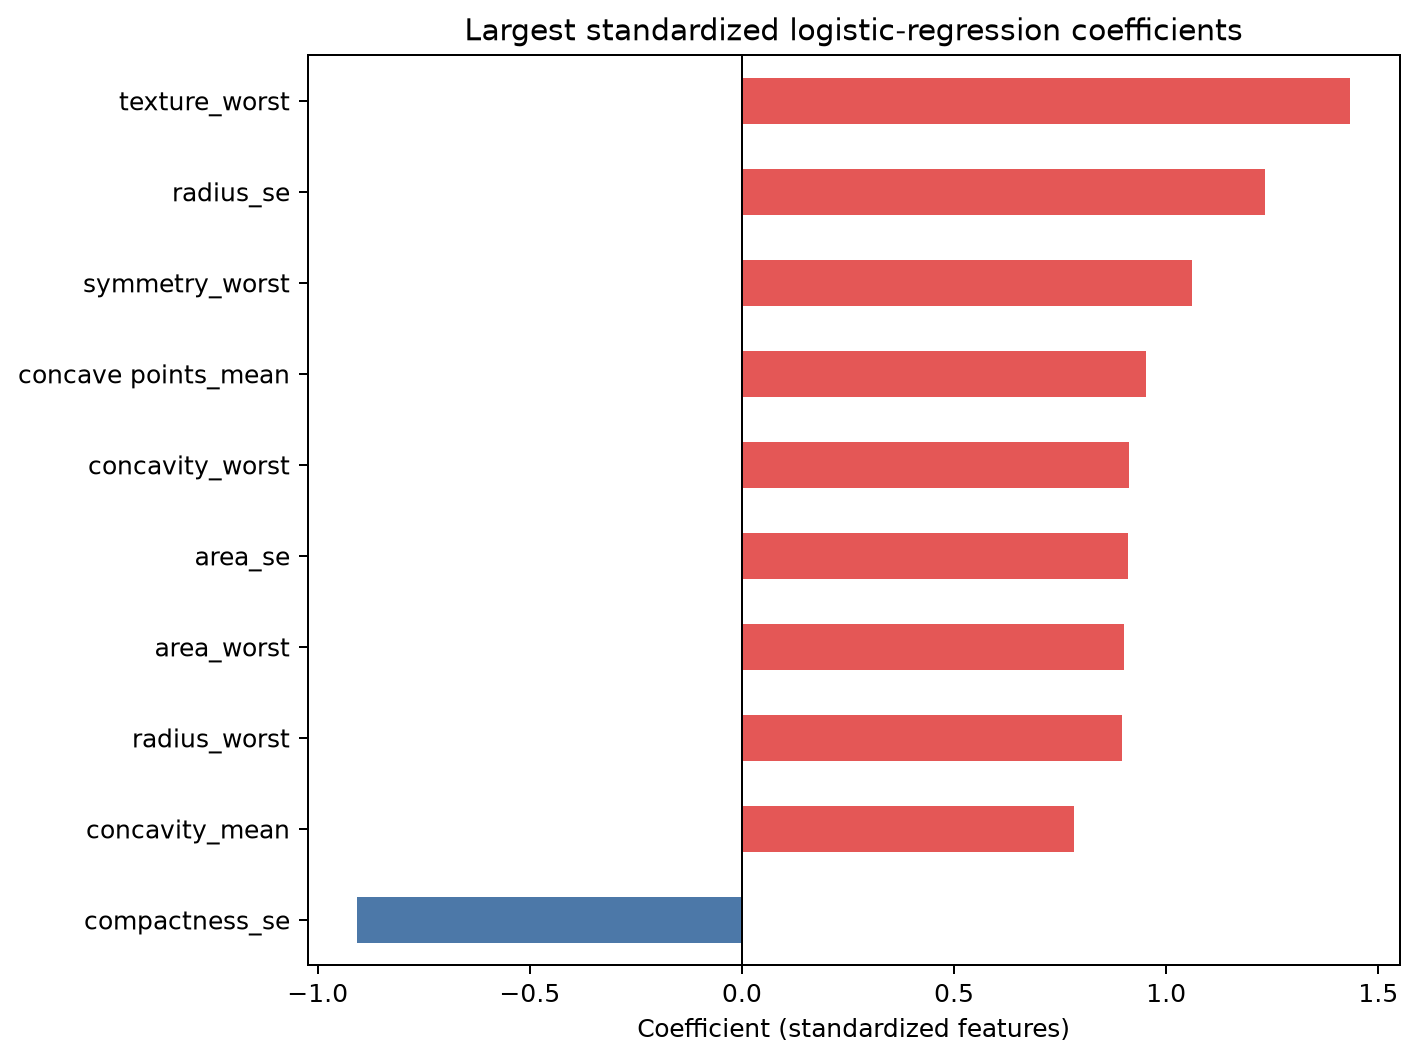

In [8]:
lr_model = clone(models["Logistic regression"]).fit(X_train, y_train)
lr = lr_model.named_steps["logisticregression"]
coef = pd.Series(lr.coef_[0], index=feature_names)
top_coef = coef.loc[coef.abs().nlargest(10).index].sort_values()
fig, ax = plt.subplots(figsize=(8, 6))
top_coef.plot.barh(ax=ax, color=["#4C78A8" if v < 0 else "#E45756" for v in top_coef])
ax.axvline(0, color="black", linewidth=.8)
ax.set(title="Largest standardized logistic-regression coefficients",
       xlabel="Coefficient (standardized features)")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "logistic_coefficients.png", bbox_inches="tight")
plt.show()


## 7. Random-forest permutation importance

This cell computes permutation importance on the held-out test set. It is a descriptive post-evaluation analysis and is not used to select or tune the model.

Permutation importance = mean decrease in test F1 after shuffling each feature.


,mean decrease in F1
concave points_worst,0.031430
texture_worst,0.030630
area_worst,0.027463
concavity_worst,0.021394
perimeter_worst,0.016135
texture_mean,0.014160
concave points_mean,0.013040
radius_worst,0.009960
smoothness_worst,0.007655
concavity_mean,0.007357


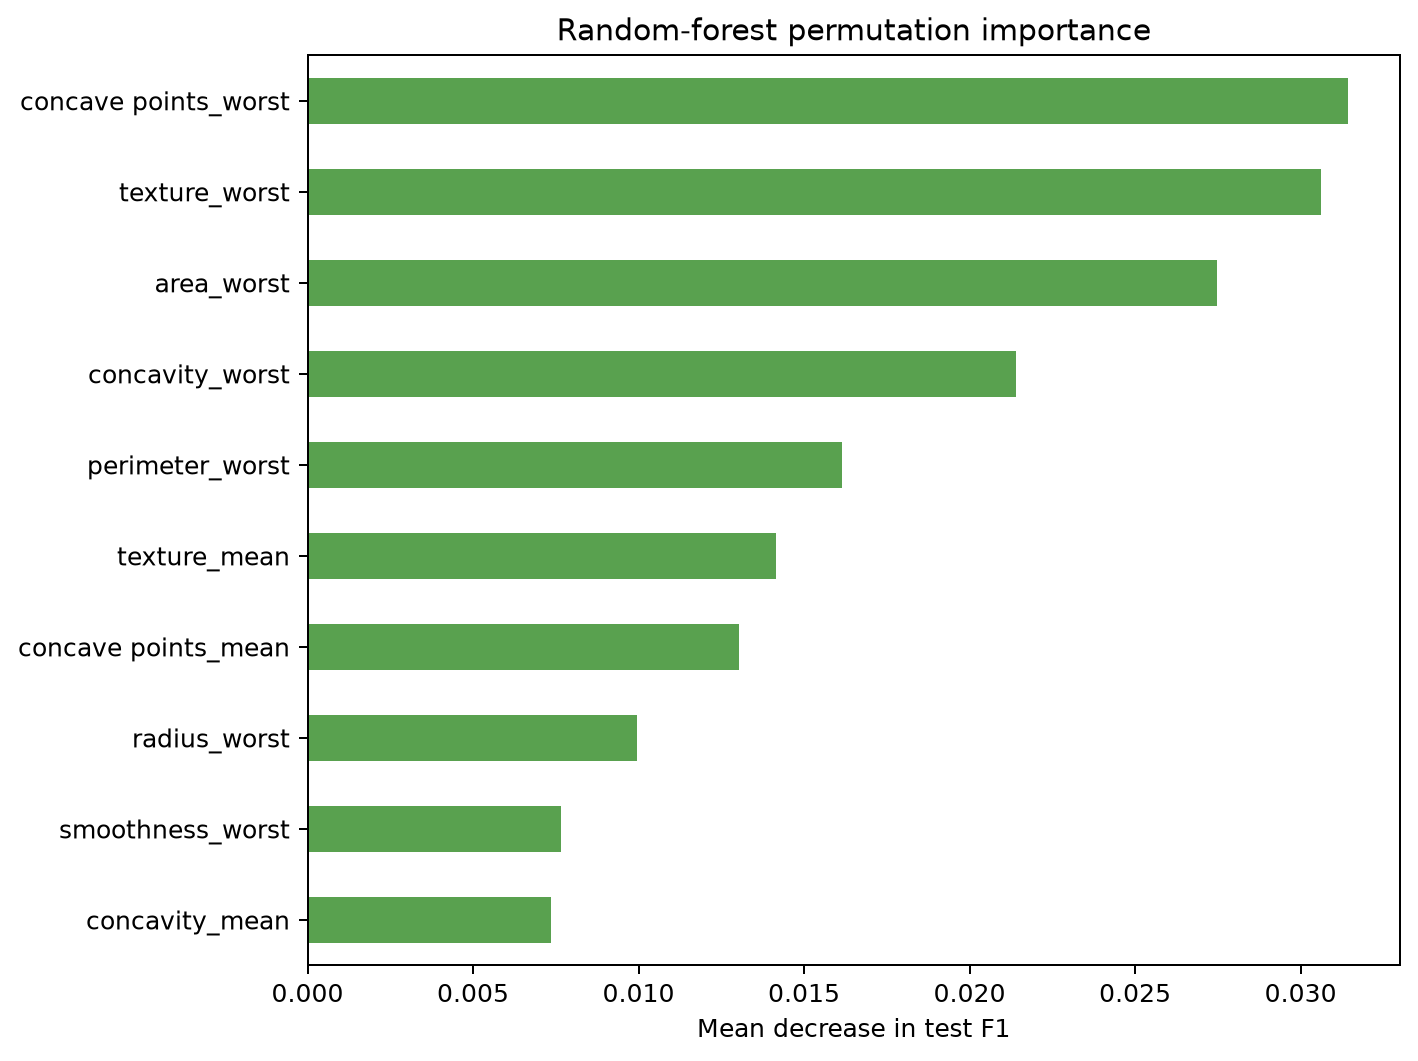

In [9]:
rf = clone(models["Random forest"]).fit(X_train, y_train)
perm = permutation_importance(rf, X_test, y_test, scoring="f1", n_repeats=30,
                              random_state=42, n_jobs=-1)
importance = pd.Series(perm.importances_mean, index=feature_names).sort_values().tail(10)
print("Permutation importance = mean decrease in test F1 after shuffling each feature.")
display(importance.sort_values(ascending=False).rename("mean decrease in F1").to_frame())
fig, ax = plt.subplots(figsize=(8, 6))
importance.plot.barh(ax=ax, color="#59A14F")
ax.set(title="Random-forest permutation importance", xlabel="Mean decrease in test F1")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "random_forest_permutation_importance.png", bbox_inches="tight")
plt.show()


## 8. Final test confusion matrix at threshold 0.5

Test F1: 0.951
Test precision: 0.975
Test recall: 0.929


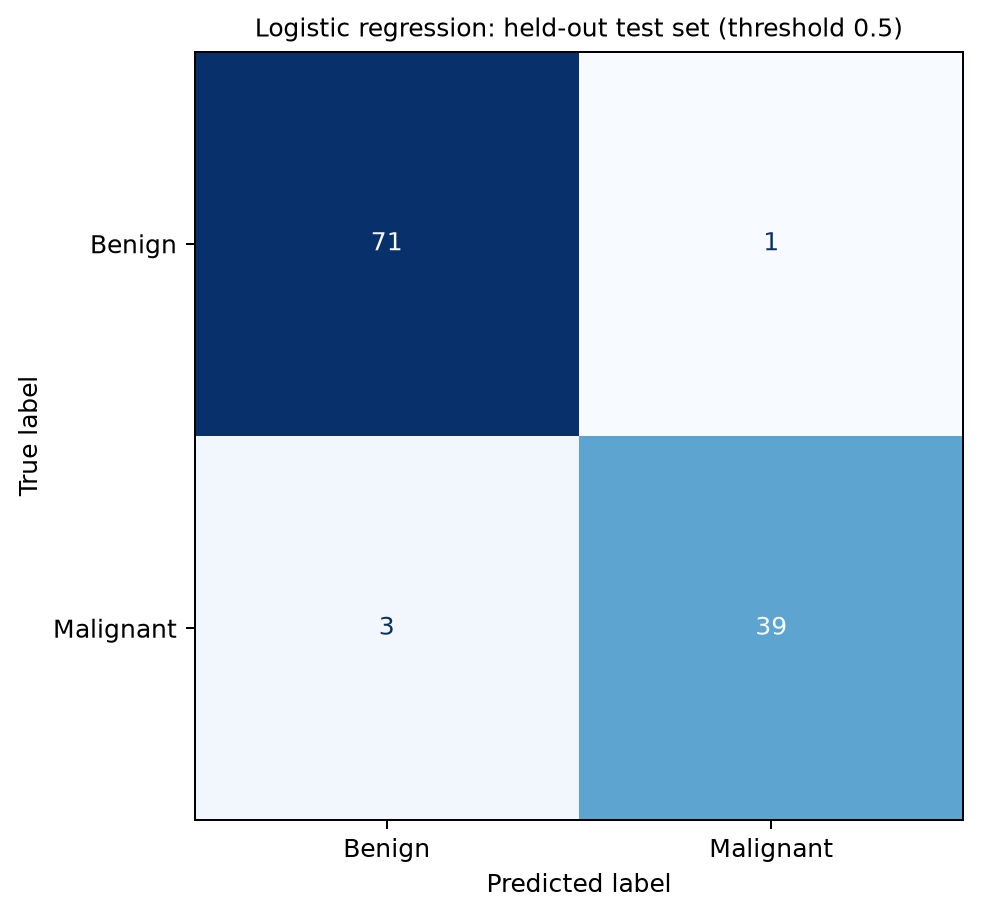

,id,actual,predicted,p_malignant
16,859983,M,B,0.061429
87,874858,M,B,0.314532
112,879523,M,B,0.491610
4,9112085,B,M,0.509155


In [10]:
test_prob = lr_model.predict_proba(X_test)[:, 1]
test_pred = (test_prob >= 0.5).astype(int)
print("Test F1:", round(f1_score(y_test, test_pred), 3))
print("Test precision:", round(precision_score(y_test, test_pred, zero_division=0), 3))
print("Test recall:", round(recall_score(y_test, test_pred, zero_division=0), 3))

fig, ax = plt.subplots(figsize=(6.2, 5.2))
ConfusionMatrixDisplay.from_predictions(y_test, test_pred, display_labels=["Benign", "Malignant"],
                                        cmap="Blues", values_format="d", colorbar=False, ax=ax)
ax.set_title("Logistic regression: held-out test set (threshold 0.5)", fontsize=10)
fig.tight_layout()
fig.savefig(FIGURE_DIR / "logistic_regression_confusion_matrix.png", bbox_inches="tight")
plt.show()

errors = pd.DataFrame({"id": ids_test.to_numpy(), "actual": y_test.to_numpy(),
                       "predicted": test_pred, "p_malignant": test_prob})
errors = errors[errors.actual != errors.predicted].copy()
errors["actual"] = errors.actual.map({0:"B", 1:"M"})
errors["predicted"] = errors.predicted.map({0:"B", 1:"M"})
display(errors.sort_values("id"))


## 9. Training-only threshold analysis

Out-of-fold probabilities are generated only from the training partition. The test set is not used to choose the threshold.

threshold=0.5: precision=0.976, recall=0.953, false positives=4
threshold=0.3: precision=0.954, recall=0.976, false positives=8


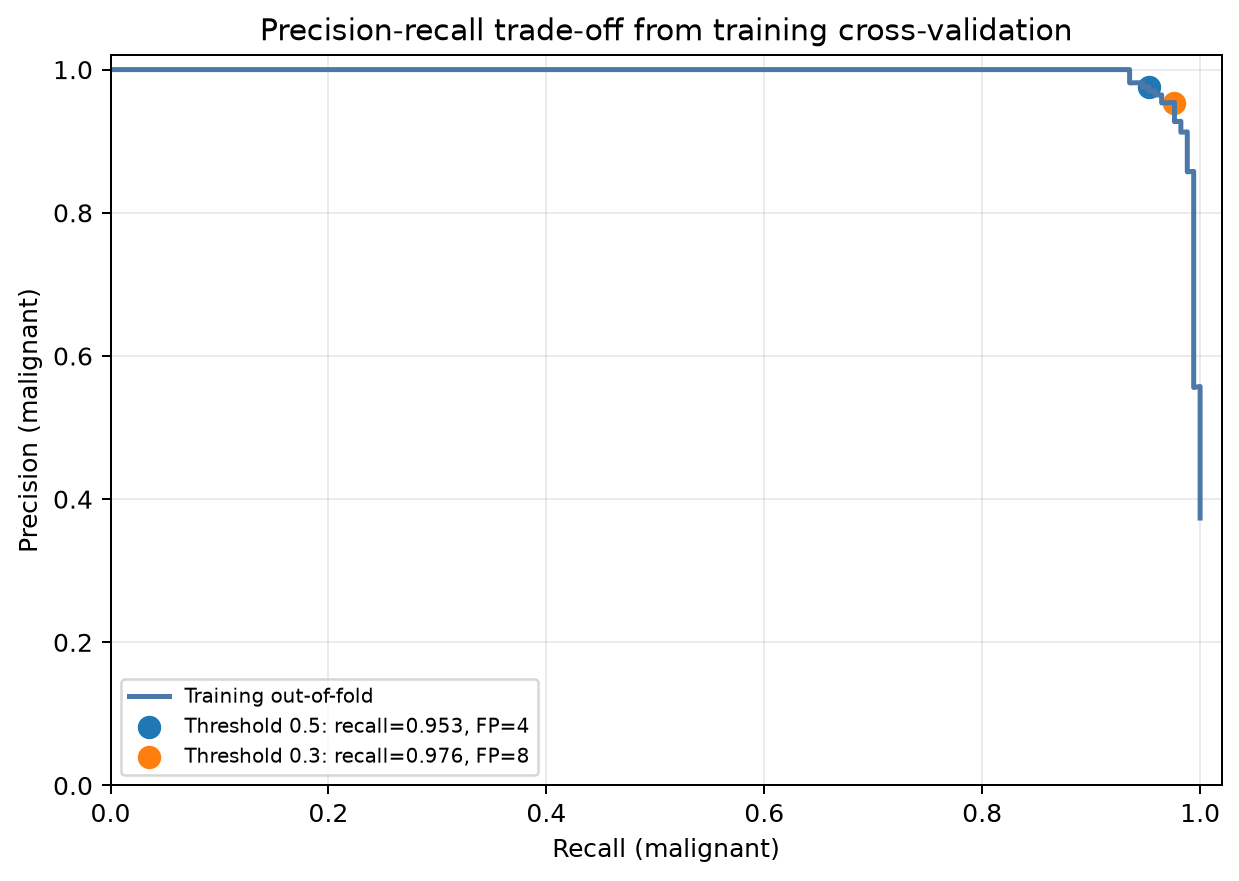

In [11]:
oof_prob = cross_val_predict(lr_model, X_train, y_train, cv=cv, method="predict_proba")[:, 1]
pr, rc, thresholds = precision_recall_curve(y_train, oof_prob)
fig, ax = plt.subplots(figsize=(7, 5))
ax.plot(rc, pr, color="#4C78A8", linewidth=2, label="Training out-of-fold")
for threshold in (0.5, 0.3):
    pred = (oof_prob >= threshold).astype(int)
    r = recall_score(y_train, pred, zero_division=0)
    pval = precision_score(y_train, pred, zero_division=0)
    fp = int(((pred == 1) & (y_train.to_numpy() == 0)).sum())
    ax.scatter(r, pval, s=70, label=f"Threshold {threshold:.1f}: recall={r:.3f}, FP={fp}")
    print(f"threshold={threshold:.1f}: precision={pval:.3f}, recall={r:.3f}, false positives={fp}")
ax.set(xlabel="Recall (malignant)", ylabel="Precision (malignant)",
       title="Precision-recall trade-off from training cross-validation", xlim=(0,1.02), ylim=(0,1.02))
ax.grid(alpha=.25); ax.legend(loc="best", fontsize=8)
fig.tight_layout()
fig.savefig(FIGURE_DIR / "precision_recall_curve.png", bbox_inches="tight")
plt.show()


## 10. Local explanations for the errors

The plot decomposes the fitted logistic-regression log-odds into standardized feature contributions for the test errors. Positive and negative values show the direction in which each feature moves the model score; they are not causal effects.

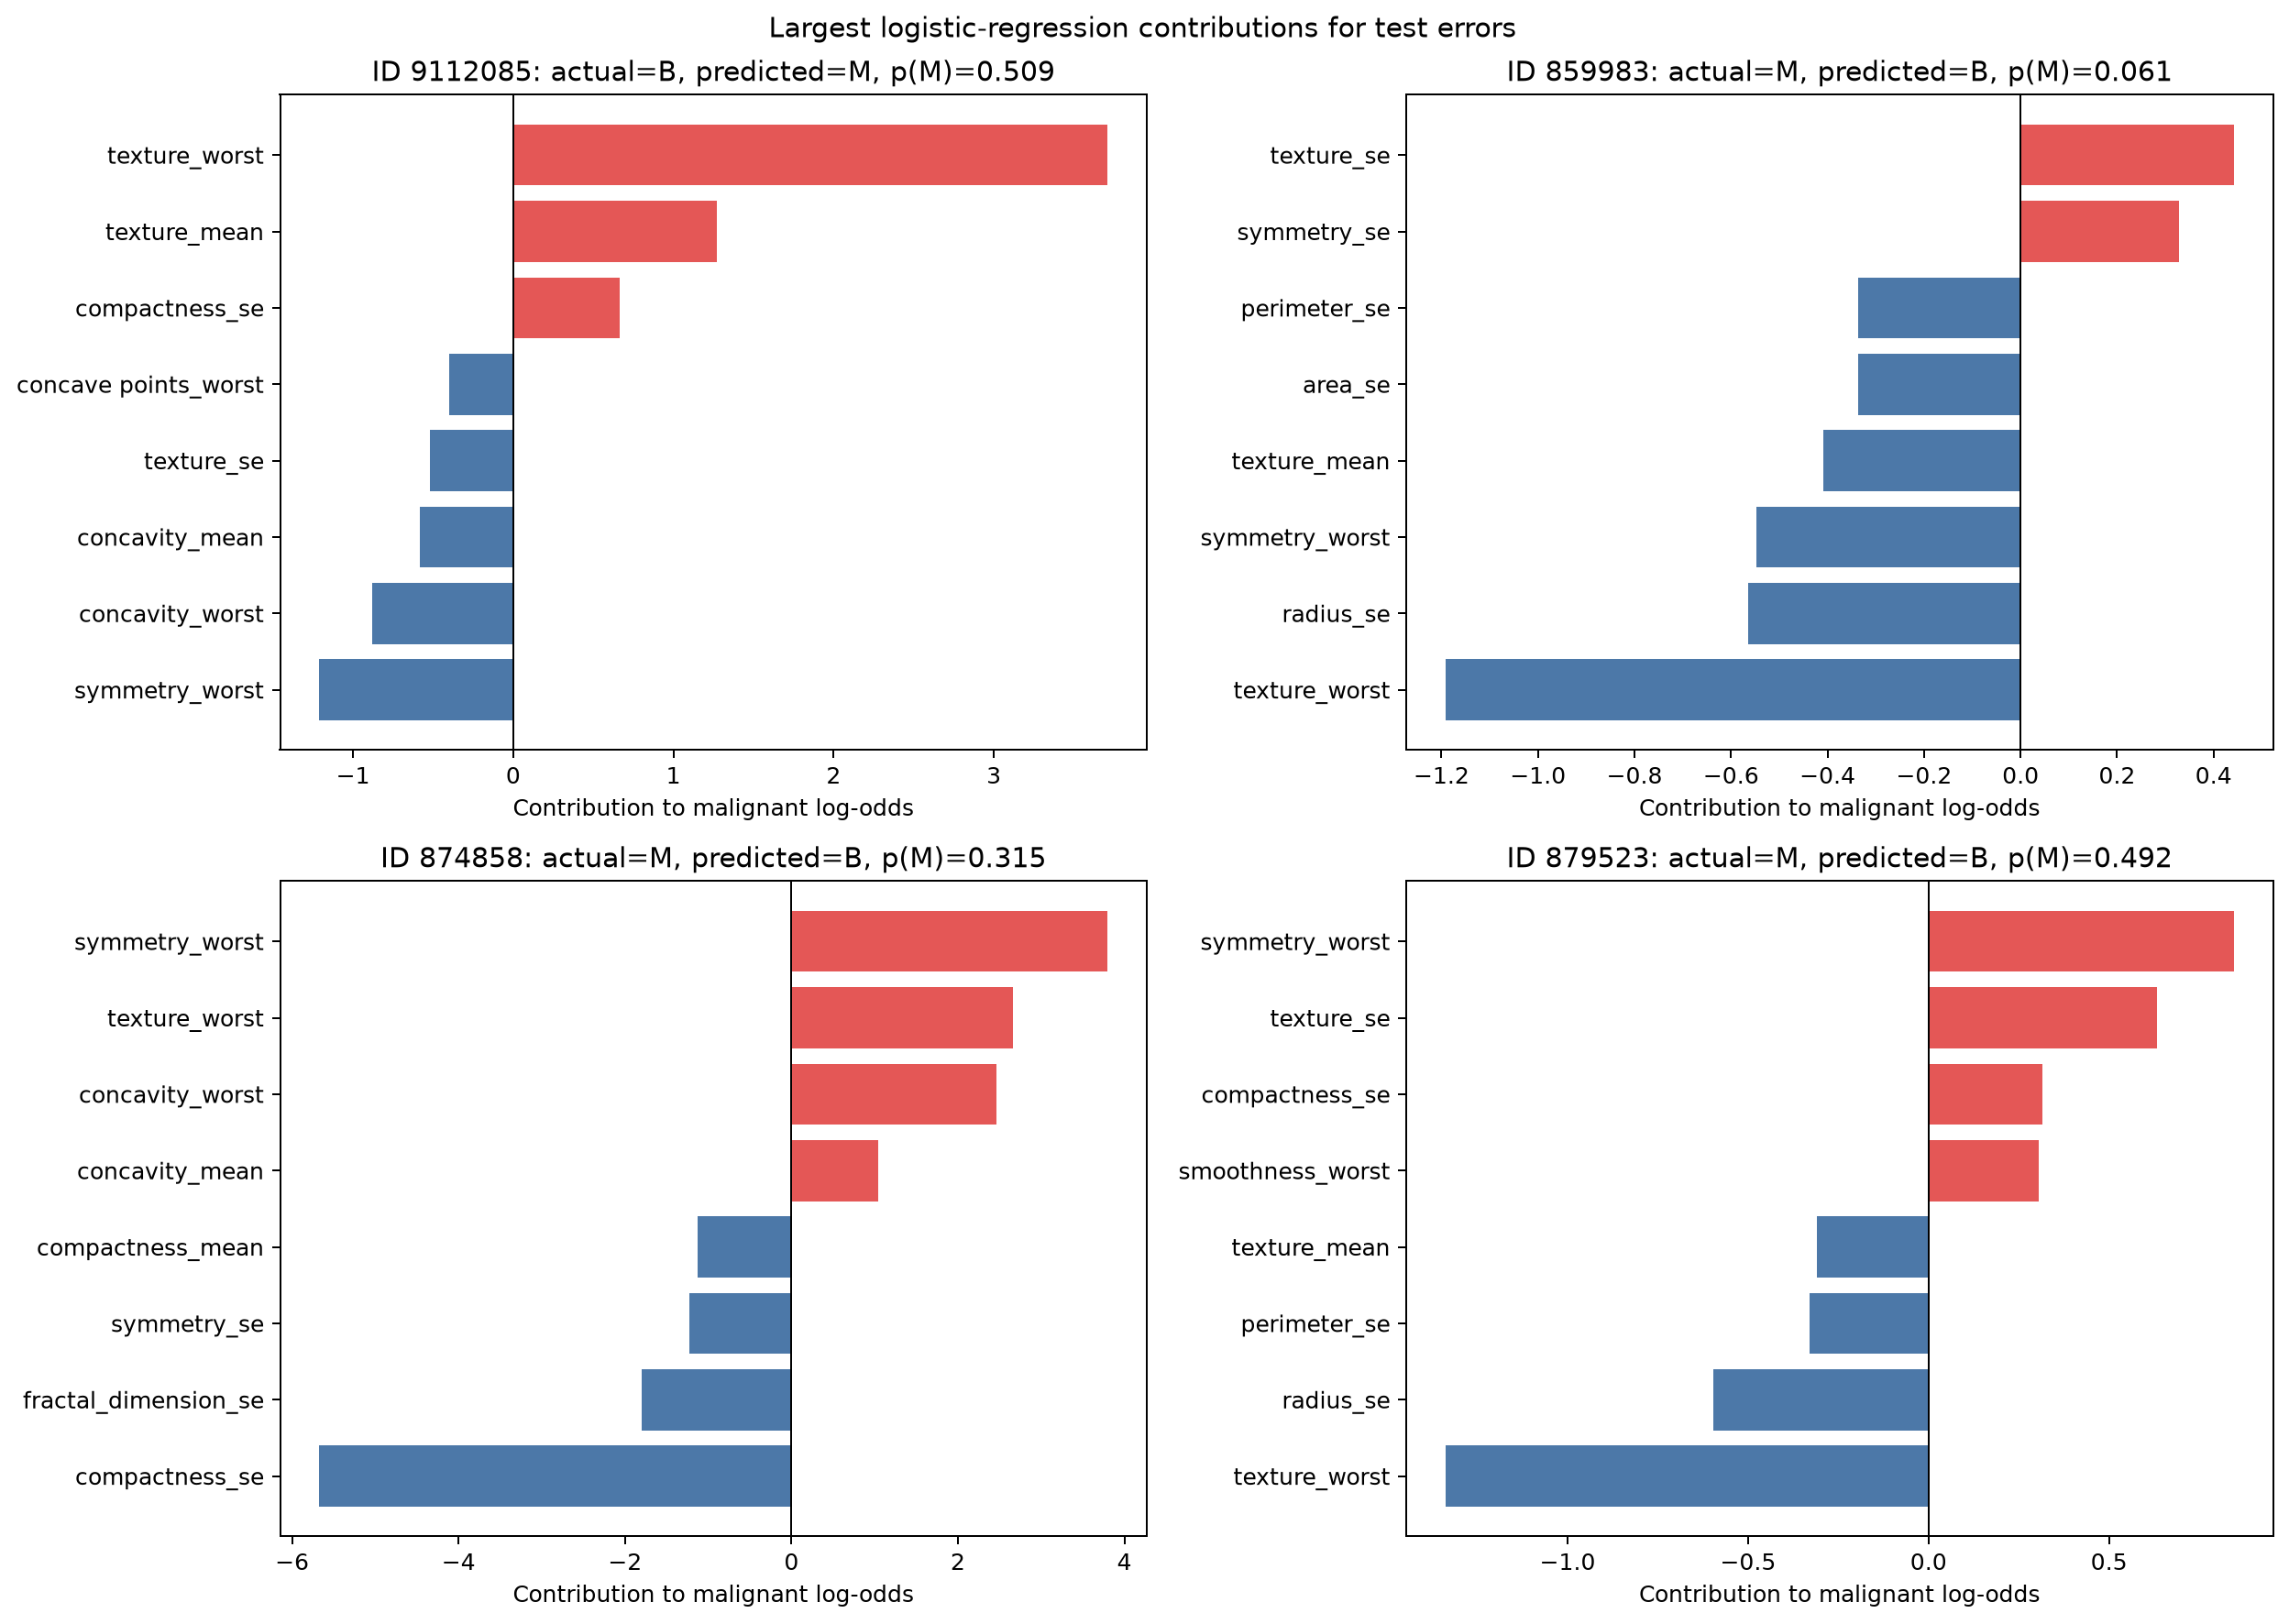

In [12]:
scaler = lr_model.named_steps["standardscaler"]
X_test_scaled = pd.DataFrame(scaler.transform(X_test), columns=feature_names, index=X_test.index)
contrib = X_test_scaled.mul(coef, axis=1)
error_idx = np.flatnonzero(y_test.to_numpy() != test_pred)
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
for ax, row_idx in zip(axes.ravel(), error_idx):
    case_index = X_test.index[row_idx]
    vals = contrib.loc[case_index]
    top = vals.loc[vals.abs().nlargest(8).index].sort_values()
    ax.barh(top.index, top.values, color=["#4C78A8" if v < 0 else "#E45756" for v in top])
    ax.axvline(0, color="black", linewidth=.8)
    case_id = ids_test.loc[case_index]
    ax.set_title(f"ID {case_id}: actual={['B','M'][int(y_test.loc[case_index])]}, "
                 f"predicted={['B','M'][int(test_pred[row_idx])]}, p(M)={test_prob[row_idx]:.3f}")
    ax.set_xlabel("Contribution to malignant log-odds")
fig.suptitle("Largest logistic-regression contributions for test errors")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "misclassified_case_contributions.png", bbox_inches="tight")
plt.show()


## 11. Proposed GUI wireframe

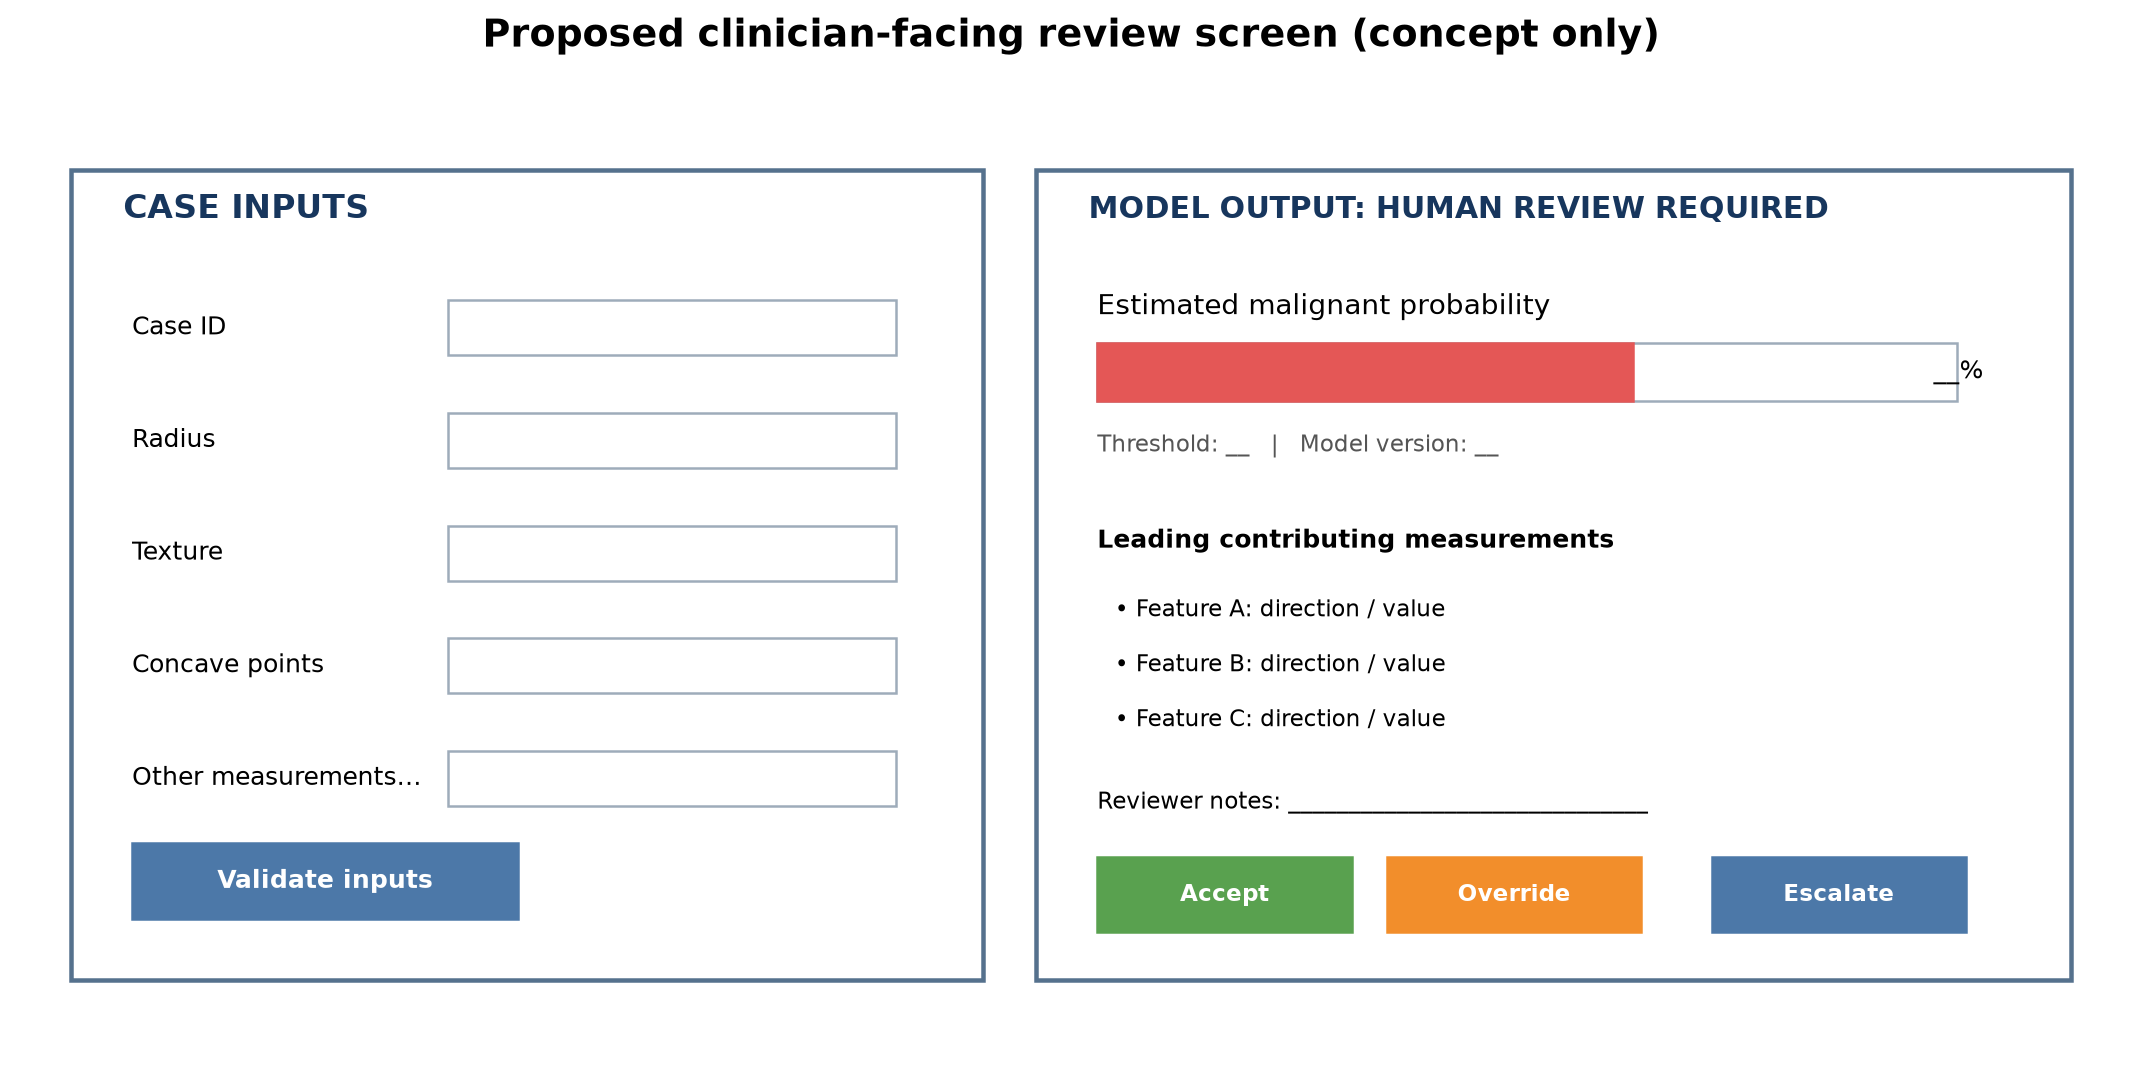

In [13]:
fig, ax = plt.subplots(figsize=(12, 6))
ax.set_xlim(0, 12); ax.set_ylim(0, 7); ax.axis("off")
# Panel frames
for x,y,w,h in [(0.3,0.5,5.2,5.9),(5.8,0.5,5.9,5.9)]:
    ax.add_patch(plt.Rectangle((x,y),w,h,fill=False,linewidth=1.8,edgecolor="#55718D"))
ax.text(.6,6.05,"CASE INPUTS",fontsize=13,weight="bold",color="#17365D")
ax.text(6.1,6.05,"MODEL OUTPUT: HUMAN REVIEW REQUIRED",fontsize=12,weight="bold",color="#17365D")
for j,label in enumerate(["Case ID", "Radius", "Texture", "Concave points", "Other measurements…"]):
    y=5.25-j*.82
    ax.text(.65,y,label,fontsize=10,va="center")
    ax.add_patch(plt.Rectangle((2.45,y-.20),2.55,.40,fill=False,edgecolor="#9EACBA"))
ax.add_patch(plt.Rectangle((.65,.95),2.2,.55,color="#4C78A8")); ax.text(1.75,1.22,"Validate inputs",ha="center",va="center",color="white",weight="bold")
ax.text(6.15,5.35,"Estimated malignant probability",fontsize=11)
ax.add_patch(plt.Rectangle((6.15,4.72),4.9,.42,fill=False,edgecolor="#9EACBA"))
ax.add_patch(plt.Rectangle((6.15,4.72),3.05,.42,color="#E45756")); ax.text(11.2,4.93,"__%",va="center",ha="right")
ax.text(6.15,4.35,"Threshold: __   |   Model version: __",fontsize=9,color="#555555")
ax.text(6.15,3.65,"Leading contributing measurements",fontsize=10,weight="bold")
ax.text(6.25,3.15,"• Feature A: direction / value",fontsize=9)
ax.text(6.25,2.75,"• Feature B: direction / value",fontsize=9)
ax.text(6.25,2.35,"• Feature C: direction / value",fontsize=9)
ax.text(6.15,1.75,"Reviewer notes: ______________________________",fontsize=9)
for x,label,color in [(6.15,"Accept", "#59A14F"),(7.8,"Override", "#F28E2B"),(9.65,"Escalate", "#4C78A8")]:
    ax.add_patch(plt.Rectangle((x,.85),1.45,.55,color=color)); ax.text(x+.725,1.12,label,ha="center",va="center",color="white",weight="bold",fontsize=9)
fig.suptitle("Proposed clinician-facing review screen (concept only)",fontsize=15,weight="bold")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "gui_wireframe.png", bbox_inches="tight")
plt.show()


## 12. Proposed Git folder structure figure

Saved figures:
 - decision_tree_depth3.png
 - diagnosis_counts.png
 - feature_comparisons.png
 - feature_correlation_heatmap.png
 - gui_wireframe.png
 - logistic_coefficients.png
 - logistic_l1_coefficients.png
 - logistic_regression_confusion_matrix.png
 - misclassified_case_contributions.png
 - precision_recall_curve.png
 - radius_vs_concave_points.png
 - random_forest_permutation_importance.png
 - repository_structure.png


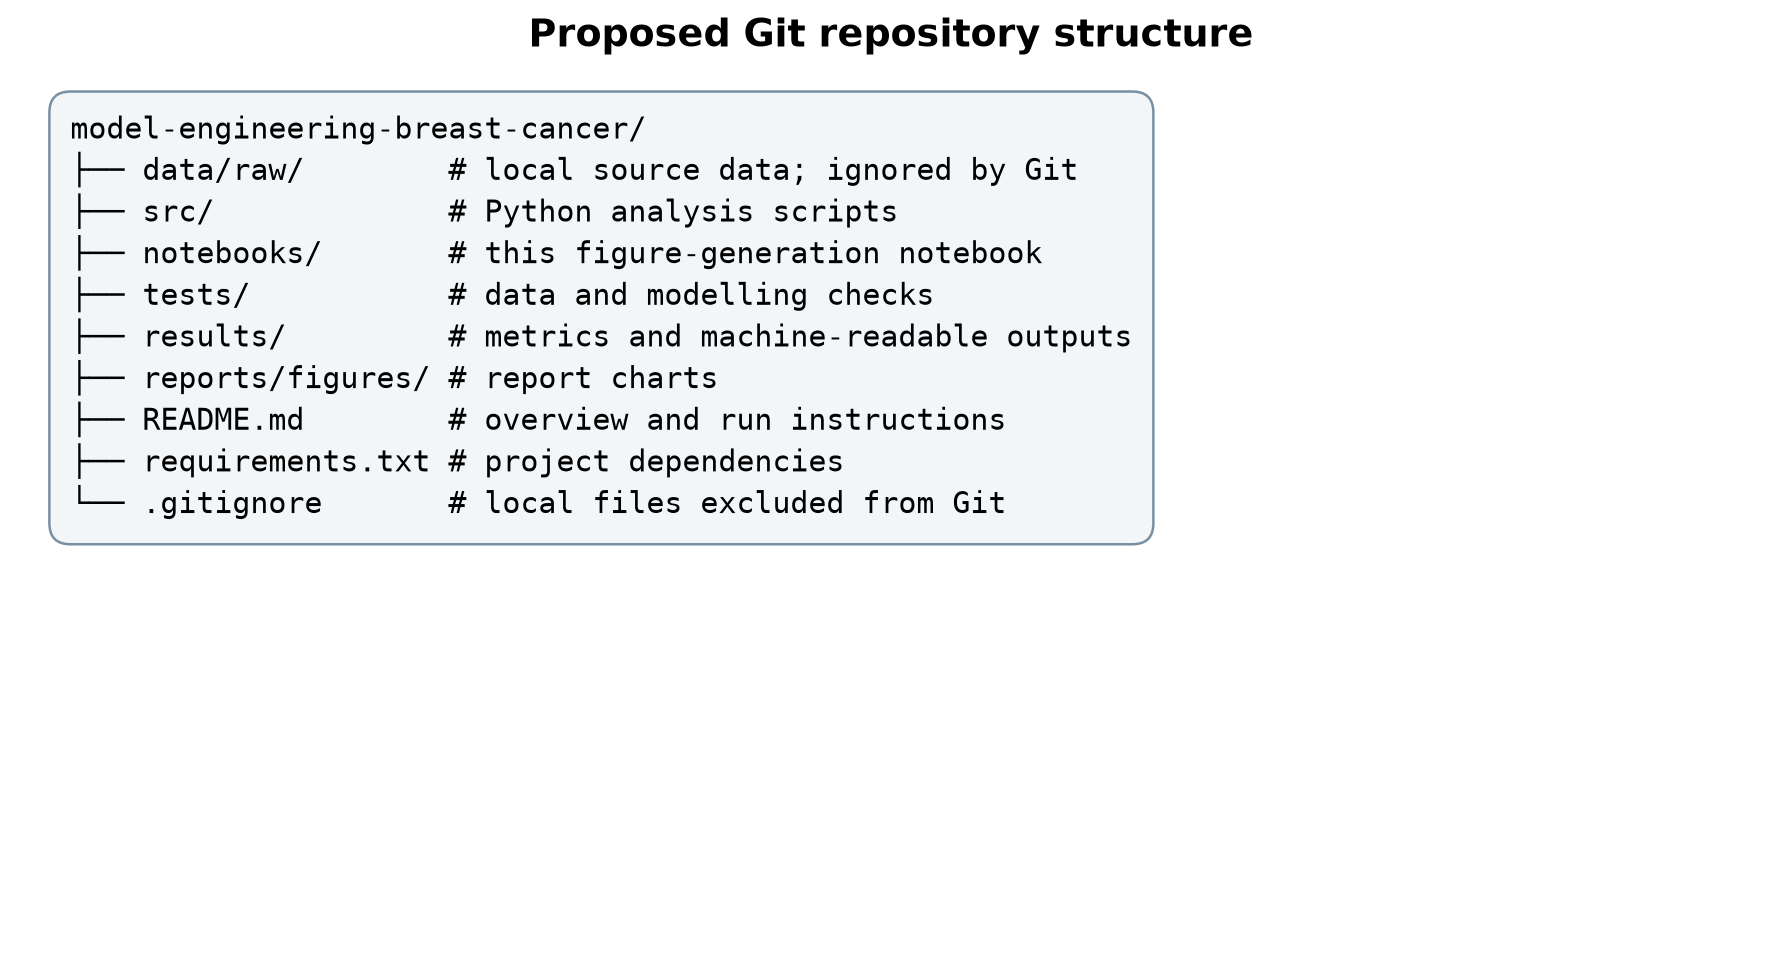

In [14]:
tree_text = """model-engineering-breast-cancer/
├── data/raw/        # local source data; ignored by Git
├── src/             # Python analysis scripts
├── notebooks/       # this figure-generation notebook
├── tests/           # data and modelling checks
├── results/         # metrics and machine-readable outputs
├── reports/figures/ # report charts
├── README.md        # overview and run instructions
├── requirements.txt # project dependencies
└── .gitignore       # local files excluded from Git"""
fig, ax = plt.subplots(figsize=(10, 5.5)); ax.axis("off")
ax.text(.03,.97,tree_text,va="top",ha="left",family="monospace",fontsize=12,
        bbox=dict(boxstyle="round,pad=.7",facecolor="#F3F6F8",edgecolor="#7890A4"))
ax.set_title("Proposed Git repository structure",fontsize=15,weight="bold",pad=16)
fig.tight_layout()
fig.savefig(FIGURE_DIR / "repository_structure.png", bbox_inches="tight")
plt.show()

print("Saved figures:")
for path in sorted(FIGURE_DIR.glob("*.png")):
    print(" -", path.name)


In [15]:
# Save machine-readable outputs from this run.
import json
RESULTS_DIR = PROJECT_ROOT / "results"
RESULTS_DIR.mkdir(exist_ok=True)
cv_results.to_csv(RESULTS_DIR / "cross_validation.csv")
errors.to_csv(RESULTS_DIR / "test_errors.csv", index=False)
summary = {
    "split": {"train": len(X_train), "test": len(X_test), "random_state": 42},
    "cv": {"folds": 5, "shuffle": True, "random_state": 42},
    "random_forest_trees": 300,
    "l1": {"f1_mean": float(l1_scores["test_f1"].mean()), "f1_sd": float(l1_scores["test_f1"].std()), "features": len(selected_l1)},
    "test": {"threshold": 0.5, "f1": float(f1_score(y_test, test_pred)), "precision": float(precision_score(y_test, test_pred)), "recall": float(recall_score(y_test, test_pred))},
    "thresholds": [{"threshold": t, "precision": float(precision_score(y_train, oof_prob >= t)), "recall": float(recall_score(y_train, oof_prob >= t)), "false_positives": int(((oof_prob >= t) & (y_train.to_numpy() == 0)).sum())} for t in (0.5, 0.3)]
}
(RESULTS_DIR / "metrics.json").write_text(json.dumps(summary, indent=2) + "\n")
print("Saved metrics, cross-validation results, and test errors in results/.")


Saved metrics, cross-validation results, and test errors in results/.
